<center>

$\Huge \textbf{Universidad Tecmilenio}$  
<p align="center">
  <img src="https://sic.cultura.gob.mx/images/135155" alt="Tecmilenio" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Actividad 05-Design thinking, definiendo e ideando}$  

$\Large \textit{Gestión de Proyectos de Inteligencia Artificial}$    

\begin{array}{rl}
\textbf{Docente:} & Dr. Eliskar Roger Altamirano Pariente \\[6pt]
\textbf{Alumnos:} & Emilio Páez García \\[6pt]
\textbf{Fecha de entrega:} & 18/10/2026
\end{array}

</center>

$\Large \textit{Predicción del precio de automóviles con MLflow}$  

**Dataset:** Automobile (UCI Machine Learning Repository, ID 10).  
**Objetivo:** preparar datos, comparar Regresión Lineal y Random Forest, ajustar hiperparámetros, evaluar con validación cruzada y registrar los experimentos en MLflow.

Se usa price como variable objetivo. El dataset original contiene 205 automóviles y valores faltantes representados como `?`.

In [ ]:
# Importación de librerías

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import mlflow
import mlflow.sklearn

# Definición de ruta
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "fuentes").exists() and (PROJECT_DIR / "Actividad_Automobile_MLflow").exists():
    PROJECT_DIR = PROJECT_DIR / "Actividad_Automobile_MLflow"
sys.path.insert(0, str(PROJECT_DIR / "fuentes"))
from datos_prep import load_uci_automobile, clean_automobile

In [22]:
# Descarga y conservación de los datos originales

raw_dir = PROJECT_DIR / "datos" / "datos_ini"
clean_dir = PROJECT_DIR / "datos" / "datos_limp"
raw_dir.mkdir(parents=True, exist_ok=True)
clean_dir.mkdir(parents=True, exist_ok=True)
raw_path = raw_dir / "automobile_original.csv"

if raw_path.exists():
    df_raw = pd.read_csv(raw_path, na_values=["?"])
else:
    df_raw = load_uci_automobile()
    df_raw.to_csv(raw_path, index=False)

print("Dimensiones originales:", df_raw.shape)
display(df_raw.head())
print("\nValores faltantes por columna:")
display(df_raw.isna().sum().sort_values(ascending=False).head(15))

Dimensiones originales: (205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,4.0,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,4.0,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0



Valores faltantes por columna:


normalized-losses    41
stroke                4
price                 4
bore                  4
horsepower            2
peak-rpm              2
num-of-doors          2
symboling             0
fuel-type             0
make                  0
wheel-base            0
engine-location       0
drive-wheels          0
body-style            0
aspiration            0
dtype: int64

In [ ]:
# Limpieza y guardado

df_clean = clean_automobile(df_raw)
clean_path = clean_dir / "automobile_limpio.csv"
df_clean.to_csv(clean_path, index=False)

print("Dimensiones limpias:", df_clean.shape)
print("Faltantes restantes:", int(df_clean.isna().sum().sum()))
display(df_clean.head())
display(df_clean.describe(include="all").T.head(15))

Dimensiones limpias: (201, 26)
Faltantes restantes: 0


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,115.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,115.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,115.0,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,4.0,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,4.0,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
symboling,201.0,NaN,NaN,NaN,0.840796,1.254802,-2.0,0.0,1.0,2.0,3.0
normalized-losses,201.0,NaN,NaN,NaN,120.711443,32.111623,65.0,101.0,115.0,137.0,256.0
make,201,22,toyota,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel-type,201,2,gas,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,201,2,std,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num-of-doors,201.0,NaN,NaN,NaN,3.144279,0.992008,2.0,2.0,4.0,4.0,4.0
body-style,201,5,sedan,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drive-wheels,201,3,fwd,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine-location,201,2,front,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheel-base,201.0,NaN,NaN,NaN,98.797015,6.066366,86.6,94.5,97.0,102.4,120.9


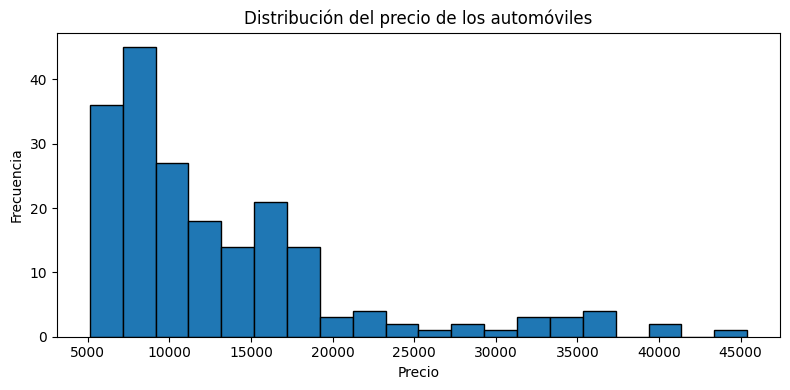

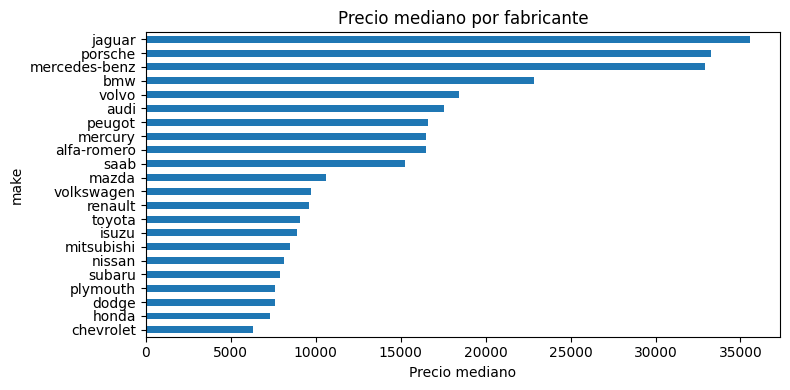

In [24]:
# Exploración rápida de los datos

plt.figure(figsize=(8, 4))
plt.hist(df_clean["price"], bins=20, edgecolor="black")
plt.title("Distribución del precio de los automóviles")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
df_clean.groupby("make")["price"].median().sort_values().plot(kind="barh")
plt.title("Precio mediano por fabricante")
plt.xlabel("Precio mediano")
plt.tight_layout()
plt.show()

In [25]:
# Separación de variables y preprocesamiento

TARGET = "price"
X = df_clean.drop(columns=[TARGET, "symboling"], errors="ignore")
y = pd.to_numeric(df_clean[TARGET], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)
print("Variables numéricas:", len(numeric_features))
print("Variables categóricas:", len(categorical_features))

Entrenamiento: (160, 24) Prueba: (41, 24)
Variables numéricas: 16
Variables categóricas: 8


In [26]:
# Configuración de MLflow con SQLite

tracking_dir = PROJECT_DIR / "mlflow.db"
tracking_dir.parent.mkdir(parents=True, exist_ok=True)

# Base de datos persistente para registrar experimentos
mlflow.set_tracking_uri(f"sqlite:///{tracking_dir.resolve().as_posix()}")

mlflow.set_experiment("UCI_Automobile_Price_Regression")

# Validación cruzada de 5 particiones
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", "UCI_Automobile_Price_Regression")

Tracking URI: sqlite:///C:/Users/haaal/Desktop/Maestría/Maestría - Gestión de proyectos de inteligencia artificial/Actividad5/Actividad_Automobile_MLflow/fuentes/mlflow.db
Experimento: UCI_Automobile_Price_Regression


In [ ]:
# Modelo 1: Regresión Lineal

linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

with mlflow.start_run(run_name="LinearRegression") as run_linear:
    cv_scores = cross_val_score(
        linear_pipeline, X_train, y_train, cv=cv,
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    linear_pipeline.fit(X_train, y_train)
    pred_linear = linear_pipeline.predict(X_test)
    metrics_linear = {
        "cv_rmse": float(-cv_scores.mean()),
        "test_mae": float(mean_absolute_error(y_test, pred_linear)),
        "test_rmse": float(mean_squared_error(y_test, pred_linear) ** 0.5),
        "test_r2": float(r2_score(y_test, pred_linear))
    }
    mlflow.log_param("algorithm", "LinearRegression")
    mlflow.log_param("cv_folds", 5)
    mlflow.log_metrics(metrics_linear)
    mlflow.sklearn.log_model(
        linear_pipeline,
        artifact_path="model",
        skops_trusted_types=["numpy.dtype"]
    )
    mlflow.log_dict(metrics_linear, "metrics.json")
    linear_run_id = run_linear.info.run_id

print(metrics_linear)

2026/10/18 17:07:57 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


{'cv_rmse': 3093.3133766019937, 'test_mae': 1721.4741019152677, 'test_rmse': 2802.9591885848204, 'test_r2': 0.9357843283078487}


In [ ]:
# Modelo 2: Random Forest y Grid Search

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])
param_grid = {
    "model__n_estimators": [100, 250],
    "model__max_depth": [None, 8, 14],
    "model__min_samples_leaf": [1, 2]
}
search = GridSearchCV(
    rf_pipeline, param_grid, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=-1,
    refit=True, return_train_score=True
)

with mlflow.start_run(run_name="RandomForest_GridSearch") as run_rf:
    search.fit(X_train, y_train)
    best_rf = search.best_estimator_
    pred_rf = best_rf.predict(X_test)
    metrics_rf = {
        "cv_rmse": float(-search.best_score_),
        "test_mae": float(mean_absolute_error(y_test, pred_rf)),
        "test_rmse": float(mean_squared_error(y_test, pred_rf) ** 0.5),
        "test_r2": float(r2_score(y_test, pred_rf))
    }
    mlflow.log_param("algorithm", "RandomForestRegressor")
    mlflow.log_param("cv_folds", 5)
    mlflow.log_params(search.best_params_)
    mlflow.log_metrics(metrics_rf)
    mlflow.sklearn.log_model(
        best_rf,
        artifact_path="model",
        skops_trusted_types=["numpy.dtype","sklearn.tree._tree.Tree"]
    )
    mlflow.log_dict(
        {"best_params": search.best_params_, "metrics": metrics_rf},
        "results.json"
    )
    rf_run_id = run_rf.info.run_id

print("Mejores parámetros:", search.best_params_)
print(metrics_rf)

2026/10/18 17:13:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Mejores parámetros: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
{'cv_rmse': 2296.4470587386636, 'test_mae': 1823.7013500642881, 'test_rmse': 2787.130811849898, 'test_r2': 0.9365075353715054}


,modelo,cv_rmse,test_mae,test_rmse,test_r2,run_id
1,Random Forest ajustado,2296.447059,1823.701350,2787.130812,0.936508,1f2b6a62b5e9486f8ec0379e730b49e1
0,Regresión Lineal,3093.313377,1721.474102,2802.959189,0.935784,6fb9dc184a89477492559c8e9d3bcaec


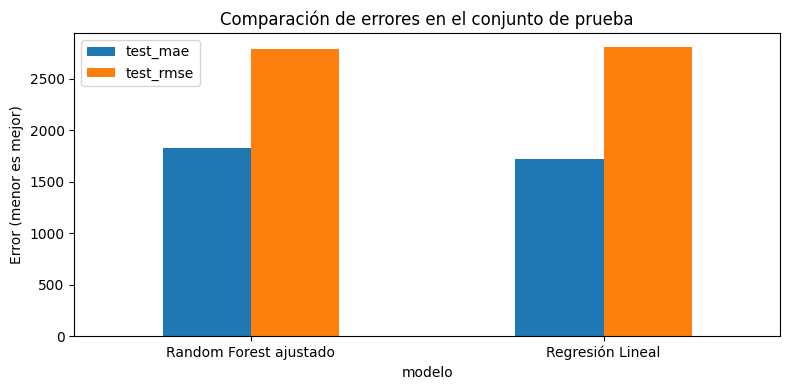

Resultados guardados en: c:\Users\haaal\Desktop\Maestría\Maestría - Gestión de proyectos de inteligencia artificial\Actividad5\Actividad_Automobile_MLflow\fuentes\datos\datos_limp\resultados_modelos.csv
MLflow tracking store: c:\Users\haaal\Desktop\Maestría\Maestría - Gestión de proyectos de inteligencia artificial\Actividad5\Actividad_Automobile_MLflow\fuentes\mlflow.db


In [ ]:
# Comparación de métricas y registro final

results = pd.DataFrame([
    {"modelo": "Regresión Lineal", **metrics_linear, "run_id": linear_run_id},
    {"modelo": "Random Forest ajustado", **metrics_rf, "run_id": rf_run_id}
]).sort_values("test_rmse")
display(results)
results.to_csv(clean_dir / "resultados_modelos.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
results.set_index("modelo")[["test_mae", "test_rmse"]].plot(kind="bar", ax=ax)
ax.set_title("Comparación de errores en el conjunto de prueba")
ax.set_ylabel("Error (menor es mejor)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Resultados guardados en:", clean_dir / "resultados_modelos.csv")
print("MLflow tracking store:", tracking_dir)